# World Development Measurement – Cluster Analysis
## Part 1: Exploratory Data Analysis (EDA)

**Objective:** understand the World Development dataset and prepare it for clustering countries by their development profile.

**Project flow (start to end):**

**Part 1 – EDA (Sections 1–12):** load data → structure & quality checks → missing values → type cleaning → drop unusable columns → distributions & outliers → country-level aggregation → log transformation → correlation analysis → summary of decisions

⬇

**Part 2 – Modelling (Sections 13–19):** link to EDA output → fill missing values → scaling → PCA (95% variance) → four clustering models (K-Means, DBSCAN, Gaussian Mixture, Hierarchical) → compare models → save models for deployment → optional extended tuning

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")

RANDOM_STATE = 42   # reused for K-Means in the next part

`display.max_columns = None` stops pandas from hiding columns (the dataset is wide), `whitegrid` makes plots easier to read, and `RANDOM_STATE` keeps K-Means reproducible later.

## 2. Load Data & Basic Structure

In [2]:
df = pd.read_excel("World_development_mesurement (1).xlsx")
df.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,Internet Usage,Lending Interest,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,NaN,0.034,0.0,0.100,71.0,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,NaN,0.128,0.0,1.032,47.0,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,NaN,0.090,0.0,NaN,57.0,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,NaN,0.054,0.0,0.155,52.0,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,NaN,0.096,0.0,NaN,52.0,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Dataset size:", df.size)

print("\nColumn names:\n")
for i, col in enumerate(df.columns, 1):
    print(i, "-", col)

Rows: 2704
Columns: 25
Dataset size: 67600

Column names:

1 - Birth Rate
2 - Business Tax Rate
3 - CO2 Emissions
4 - Country
5 - Days to Start Business
6 - Ease of Business
7 - Energy Usage
8 - GDP
9 - Health Exp % GDP
10 - Health Exp/Capita
11 - Hours to do Tax
12 - Infant Mortality Rate
13 - Internet Usage
14 - Lending Interest
15 - Life Expectancy Female
16 - Life Expectancy Male
17 - Mobile Phone Usage
18 - Number of Records
19 - Population 0-14
20 - Population 15-64
21 - Population 65+
22 - Population Total
23 - Population Urban
24 - Tourism Inbound
25 - Tourism Outbound


In [4]:
display(df.dtypes.to_frame("Data Type"))
df.info()

,Data Type
Birth Rate,float64
Business Tax Rate,object
CO2 Emissions,float64
Country,object
Days to Start Business,float64
Ease of Business,float64
Energy Usage,float64
GDP,object
Health Exp % GDP,float64
Health Exp/Capita,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   object 
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   object 
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   object 
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   object 
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Birth Rate,2585.0,NaN,NaN,NaN,0.022715,0.011338,0.007,0.013,0.02,0.031,0.053
Business Tax Rate,1423,447,44.1%,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO2 Emissions,2125.0,NaN,NaN,NaN,142307.107765,615928.805709,7.0,1360.0,8529.0,59108.0,8286892.0
Country,2704,208,Algeria,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days to Start Business,1718.0,NaN,NaN,NaN,39.999418,57.318588,1.0,13.0,26.0,45.0,694.0
Ease of Business,185.0,NaN,NaN,NaN,94.875676,54.791906,1.0,48.0,94.0,142.0,189.0
Energy Usage,1785.0,NaN,NaN,NaN,77236.840896,259923.855845,8.0,3737.0,14338.0,41852.0,2727728.0
GDP,2494,2494,"$54,790,058,957",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health Exp % GDP,2395.0,NaN,NaN,NaN,0.06417,0.026325,0.008,0.046,0.061,0.079,0.225
Health Exp/Capita,2395,1069,$15,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Findings**
- The dataset has **2,704 rows and 25 columns**.
- Six columns that should be numeric were read as text: `Business Tax Rate`, `GDP`, `Health Exp/Capita`, `Tourism Inbound`, `Tourism Outbound` (they contain `$`, `,` and `%`). They are fixed in Section 4.

## 3. Duplicates & Country Coverage

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Number of unique countries:", df["Country"].nunique())
df["Country"].value_counts().head(10)

Duplicate rows: 0
Number of unique countries: 208


Country
Algeria               13
Angola                13
Turkey                13
Ukraine               13
United Kingdom        13
Bahrain               13
Iran, Islamic Rep.    13
Iraq                  13
Israel                13
Jordan                13
Name: count, dtype: int64

**Findings**
- There are **no duplicate rows**.
- The data covers **208 countries**, each with up to 13 records (the data is a panel: several records per country). Because clustering needs **one row per country**, the data is aggregated by country in Section 7.

## 4. Missing Values (Raw Data)

In [7]:
missing_details = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100,
    "Unique Values": df.nunique()
}).sort_values("Missing Percentage", ascending=False)

display(missing_details)

,Missing Count,Missing Percentage,Unique Values
Ease of Business,2519,93.158284,185
Hours to do Tax,1288,47.633136,280
Business Tax Rate,1281,47.374260,447
Days to Start Business,986,36.464497,126
Energy Usage,919,33.986686,1721
Lending Interest,824,30.473373,351
CO2 Emissions,579,21.412722,1743
Tourism Outbound,471,17.418639,1457
Tourism Inbound,368,13.609467,1650
Health Exp % GDP,309,11.427515,145


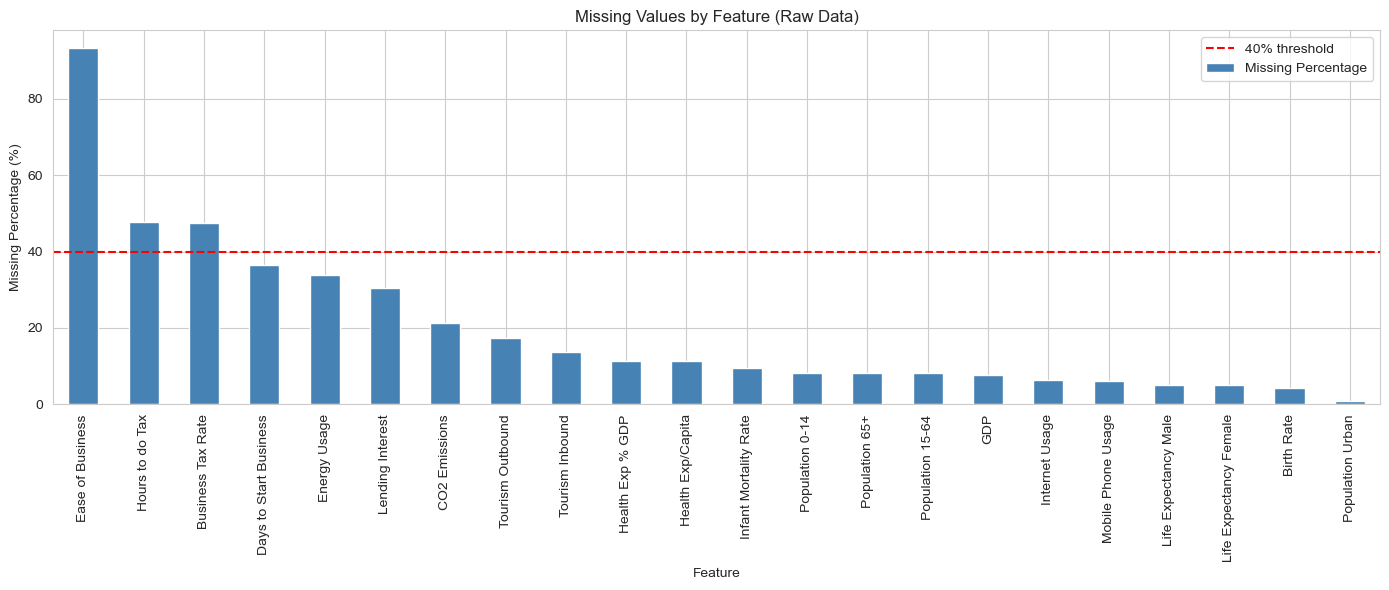

In [8]:
plt.figure(figsize=(14, 6))
missing_details[missing_details["Missing Count"] > 0]["Missing Percentage"].plot(kind="bar", color="steelblue")
plt.axhline(40, color="red", linestyle="--", label="40% threshold")
plt.title("Missing Values by Feature (Raw Data)")
plt.xlabel("Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

**Findings**
- `Ease of Business` is **~93% missing**, so it cannot be imputed reliably.
- `Hours to do Tax` and `Business Tax Rate` are ~47% missing, `Days to Start Business` ~36%, `Energy Usage` ~34%, `Lending Interest` ~30%.
- Core development indicators (life expectancy, birth rate, internet, mobile, population) are mostly under 7% missing.

## 5. Cleaning Numeric Columns

In [9]:
def clean_numeric_value(value):
    """Remove $, commas and % from text values and convert to a number (NaN if impossible)."""
    if isinstance(value, str):
        value = value.strip().replace("$", "").replace(",", "").replace("%", "")
    return pd.to_numeric(value, errors="coerce")

clean_df = df.copy()                      # original df stays untouched
cols = clean_df.columns.drop("Country")
clean_df[cols] = clean_df[cols].map(clean_numeric_value)

clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   float64
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   object 
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   float64
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   float64
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   

In [10]:
# Cleaning must not create new missing values: compare against the raw missing counts
after = clean_df.isnull().sum()
print("Columns whose missing count changed after cleaning:")
print((after - df.isnull().sum())[after != df.isnull().sum()])

Columns whose missing count changed after cleaning:
Series([], dtype: int64)


All columns except `Country` are now numeric, and conversion introduced no new missing values (the check above is empty).

## 6. Drop Unusable Columns

In [11]:
# Number of Records is constant (always 1) -> no information
# Ease of Business is ~93% missing -> cannot be imputed reliably
print("Unique values in Number of Records:", clean_df["Number of Records"].unique())
print("Missing % in Ease of Business:", round(clean_df["Ease of Business"].isnull().mean() * 100, 1))

clean_df = clean_df.drop(columns=["Number of Records", "Ease of Business"])
print("\nShape after dropping:", clean_df.shape)

Unique values in Number of Records: [1]
Missing % in Ease of Business: 93.2

Shape after dropping: (2704, 23)


`Number of Records` has a single value, so it cannot separate countries, and `Ease of Business` is almost entirely empty. Both are removed.

## 7. Distributions & Outlier Check (No Capping)

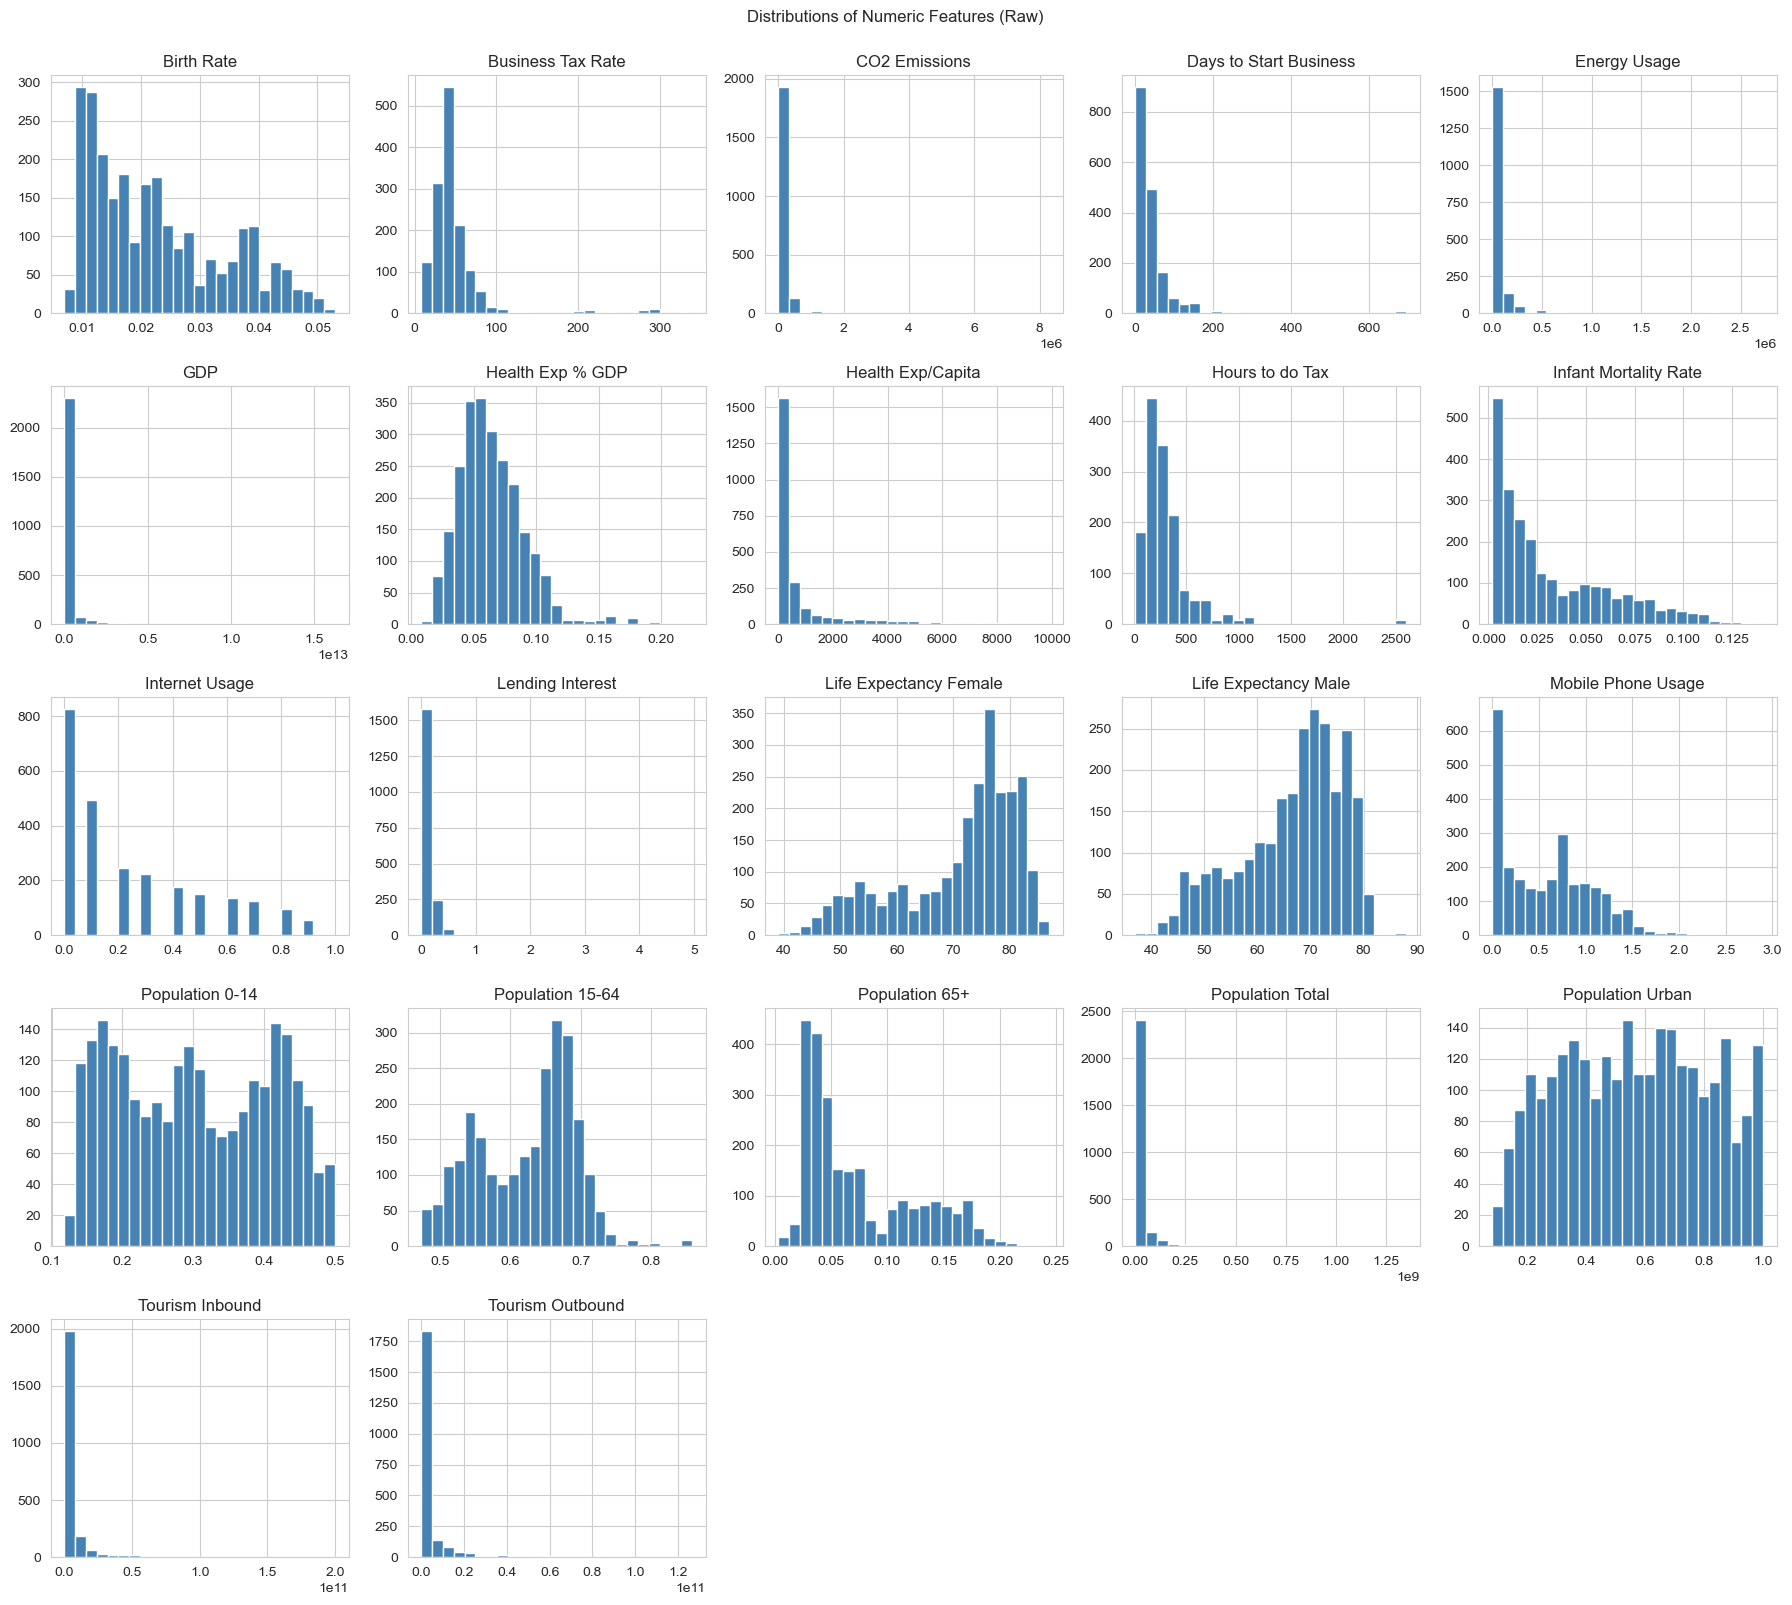

In [12]:
numeric_columns = clean_df.select_dtypes(include=np.number).columns.tolist()

clean_df[numeric_columns].hist(figsize=(18, 16), bins=25, color="steelblue")
plt.suptitle("Distributions of Numeric Features (Raw)", y=1.00)
plt.tight_layout()
plt.show()

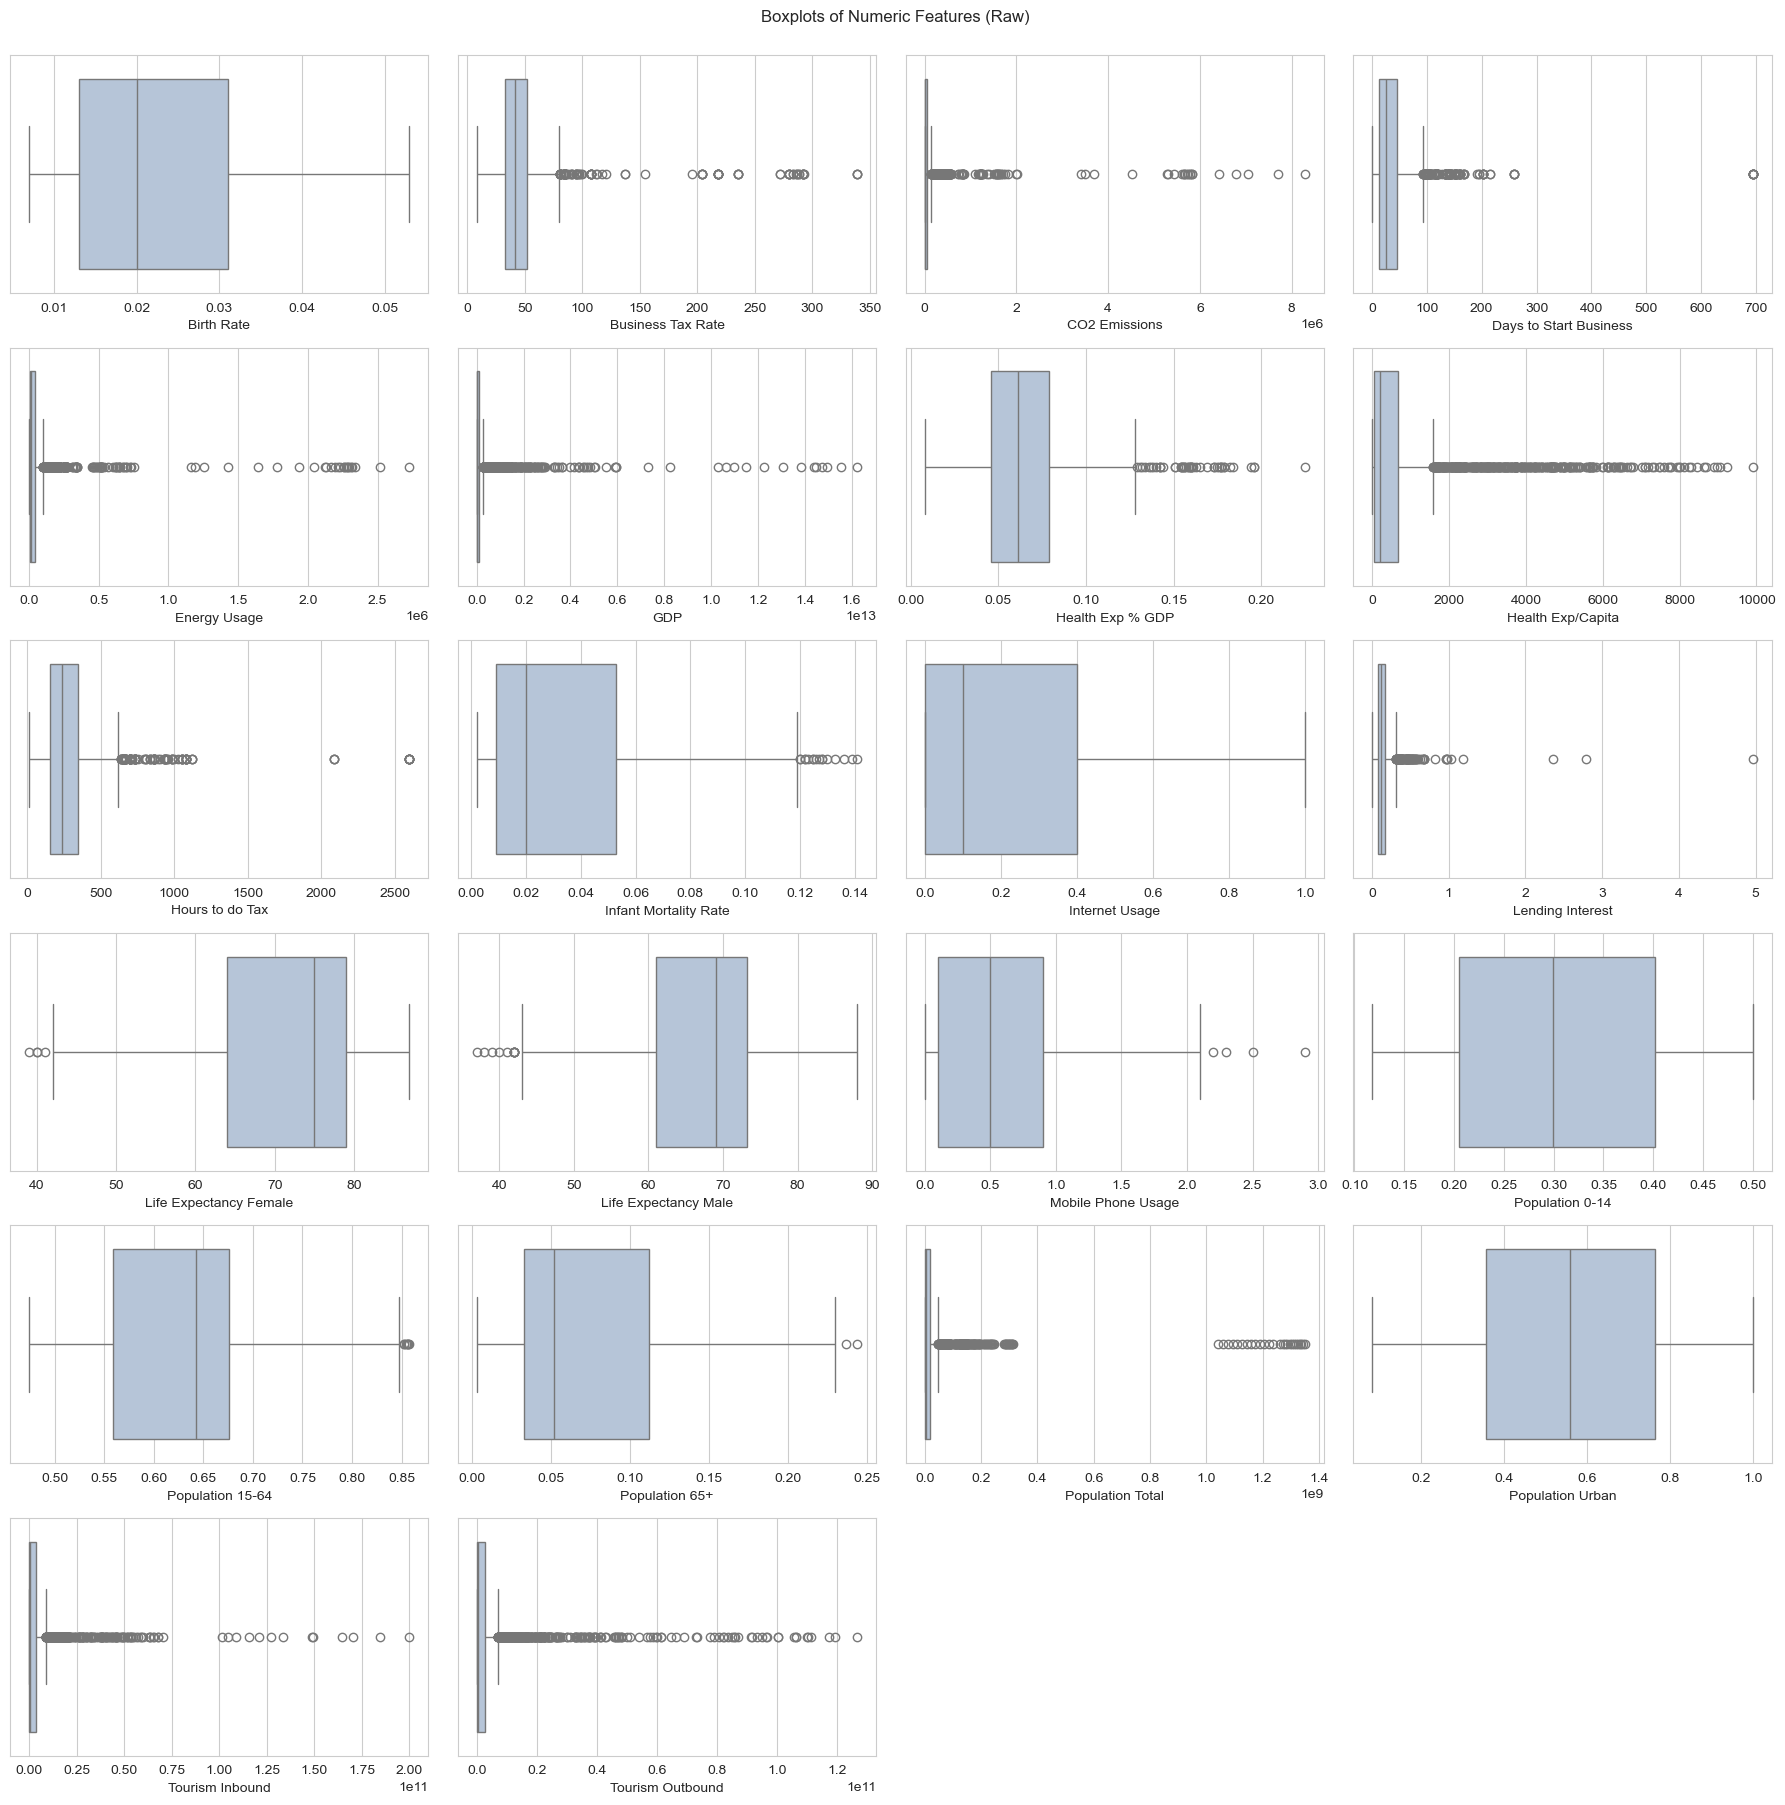

In [13]:
n = len(numeric_columns)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3 * nrows))
for ax, col in zip(axes.ravel(), numeric_columns):
    sns.boxplot(x=clean_df[col], ax=ax, color="lightsteelblue")
    ax.set_xlabel(col)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.suptitle("Boxplots of Numeric Features (Raw)", y=1.00)
plt.tight_layout()
plt.show()

In [14]:
# Summarise outliers and skewness without modifying the data
rows = []
for c in numeric_columns:
    q1, q3 = clean_df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((clean_df[c] < q1 - 1.5 * iqr) | (clean_df[c] > q3 + 1.5 * iqr)).sum()
    rows.append([c, n_out, round(n_out / clean_df[c].notna().sum() * 100, 1), round(clean_df[c].skew(), 2)])

outlier_summary = pd.DataFrame(rows, columns=["Feature", "IQR Outliers", "Outlier %", "Skewness"]) \
                    .sort_values("Skewness", ascending=False)
display(outlier_summary)

,Feature,IQR Outliers,Outlier %,Skewness
11,Lending Interest,96,5.1,15.54
5,GDP,345,13.8,9.42
18,Population Total,318,11.8,8.79
2,CO2 Emissions,317,14.9,8.65
3,Days to Start Business,138,8.0,7.44
20,Tourism Inbound,329,14.1,7.11
4,Energy Usage,272,15.2,7.06
21,Tourism Outbound,348,15.6,5.21
8,Hours to do Tax,109,7.7,4.49
1,Business Tax Rate,100,7.0,4.34


**Decision: outliers are NOT capped.**
Variables such as `GDP`, `Population Total`, `CO2 Emissions`, `Energy Usage` and `Tourism` are extremely right-skewed because countries genuinely differ by orders of magnitude. Capping at 1.5×IQR would give the USA, China or India the same value as a mid-sized economy and erase exactly the differences clustering should find. Instead, these variables are **log-transformed** (Section 9), which reduces skew while keeping the ranking of countries.

## 8. Aggregate to Country Level

In [15]:
country_df = clean_df.groupby("Country").median(numeric_only=True)

print("Record-level shape:", clean_df.shape)
print("Country-level shape:", country_df.shape)
country_df.head()

Record-level shape: (2704, 23)
Country-level shape: (208, 22)


,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,Internet Usage,Lending Interest,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Country,,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0.0440,36.30,1016.0,9.0,NaN,8.450724e+09,0.091,30.0,275.0,0.082,0.0,0.151,59.0,56.0,0.2,0.493,0.487,0.020,25631282.0,0.232,1.160000e+08,80000000.0
Albania,0.0140,41.45,4056.0,22.5,2060.0,9.132562e+09,0.061,168.0,364.0,0.017,0.1,0.130,80.0,73.0,0.6,0.258,0.654,0.089,2968028.0,0.478,1.057000e+09,989000000.0
Algeria,0.0220,72.90,103963.0,25.0,33496.5,1.170267e+11,0.037,106.0,451.0,0.028,0.1,0.080,72.0,68.0,0.6,0.282,0.673,0.045,34507214.0,0.646,3.000000e+08,504000000.0
American Samoa,0.0205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,57919.0,0.880,NaN,NaN
Andorra,0.0105,NaN,535.0,NaN,NaN,2.322164e+09,0.062,2631.0,NaN,0.003,0.6,NaN,NaN,NaN,0.8,NaN,NaN,NaN,78360.0,0.898,NaN,NaN


Each country now has one row, using the **median** of its records (robust to unusual years). Aggregation is done **before** any transformation so that every country counts once.

## 9. Missing Values (Country Level)

,Missing Count,Missing Percentage
Lending Interest,45,21.634615
Energy Usage,41,19.711538
Health Exp/Capita,23,11.057692
Business Tax Rate,23,11.057692
Days to Start Business,23,11.057692
Hours to do Tax,23,11.057692
Health Exp % GDP,23,11.057692
Tourism Outbound,22,10.576923
Infant Mortality Rate,20,9.615385
Population 0-14,16,7.692308


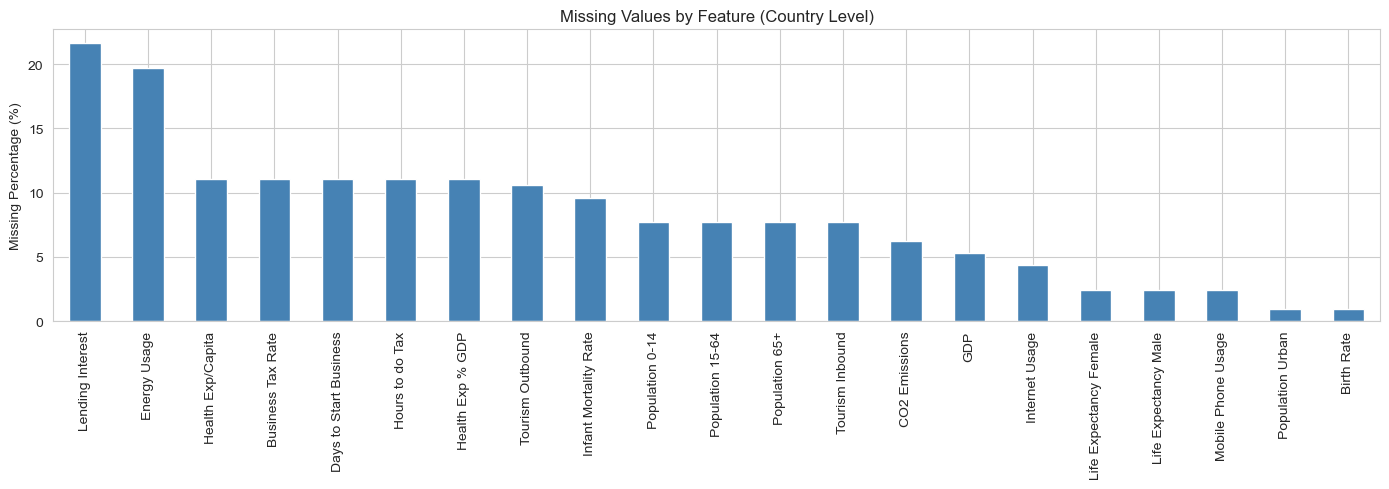

In [16]:
country_missing = pd.DataFrame({
    "Missing Count": country_df.isnull().sum(),
    "Missing Percentage": country_df.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

display(country_missing)

missing_only = country_missing[country_missing["Missing Count"] > 0]["Missing Percentage"]
if len(missing_only):
    missing_only.plot(kind="bar", figsize=(14, 5), color="steelblue")
    plt.title("Missing Values by Feature (Country Level)")
    plt.ylabel("Missing Percentage (%)")
    plt.tight_layout()
    plt.show()

**Findings**
- Aggregation reduces missingness considerably (e.g. `Hours to do Tax` falls from ~48% to ~11%).
- The highest remaining gaps are `Lending Interest` (~22%) and `Energy Usage` (~20%); most other columns are ≤ 11%.
- These gaps will be handled by **imputation in the preprocessing step** (median, or KNN), not here.

## 10. Log Transformation of Skewed Features

In [17]:
# Transform strongly right-skewed, non-negative features with log(1 + x)
skew = country_df.skew()
log_cols = [c for c in country_df.columns if skew[c] > 1 and country_df[c].min() >= 0]
print("Features log-transformed:", log_cols)

country_log = country_df.copy()
country_log[log_cols] = np.log1p(country_log[log_cols])

skew_compare = pd.DataFrame({"Skew Before": skew, "Skew After": country_log.skew()}).loc[log_cols].round(2)
display(skew_compare)

Features log-transformed: ['Business Tax Rate', 'CO2 Emissions', 'Days to Start Business', 'Energy Usage', 'GDP', 'Health Exp % GDP', 'Health Exp/Capita', 'Hours to do Tax', 'Infant Mortality Rate', 'Lending Interest', 'Population Total', 'Tourism Inbound', 'Tourism Outbound']


,Skew Before,Skew After
Business Tax Rate,4.20,0.75
CO2 Emissions,8.27,0.05
Days to Start Business,7.70,0.39
Energy Usage,7.43,-0.47
GDP,9.99,0.25
Health Exp % GDP,1.12,1.01
Health Exp/Capita,2.53,0.25
Hours to do Tax,4.56,-0.26
Infant Mortality Rate,1.01,0.96
Lending Interest,4.44,3.13


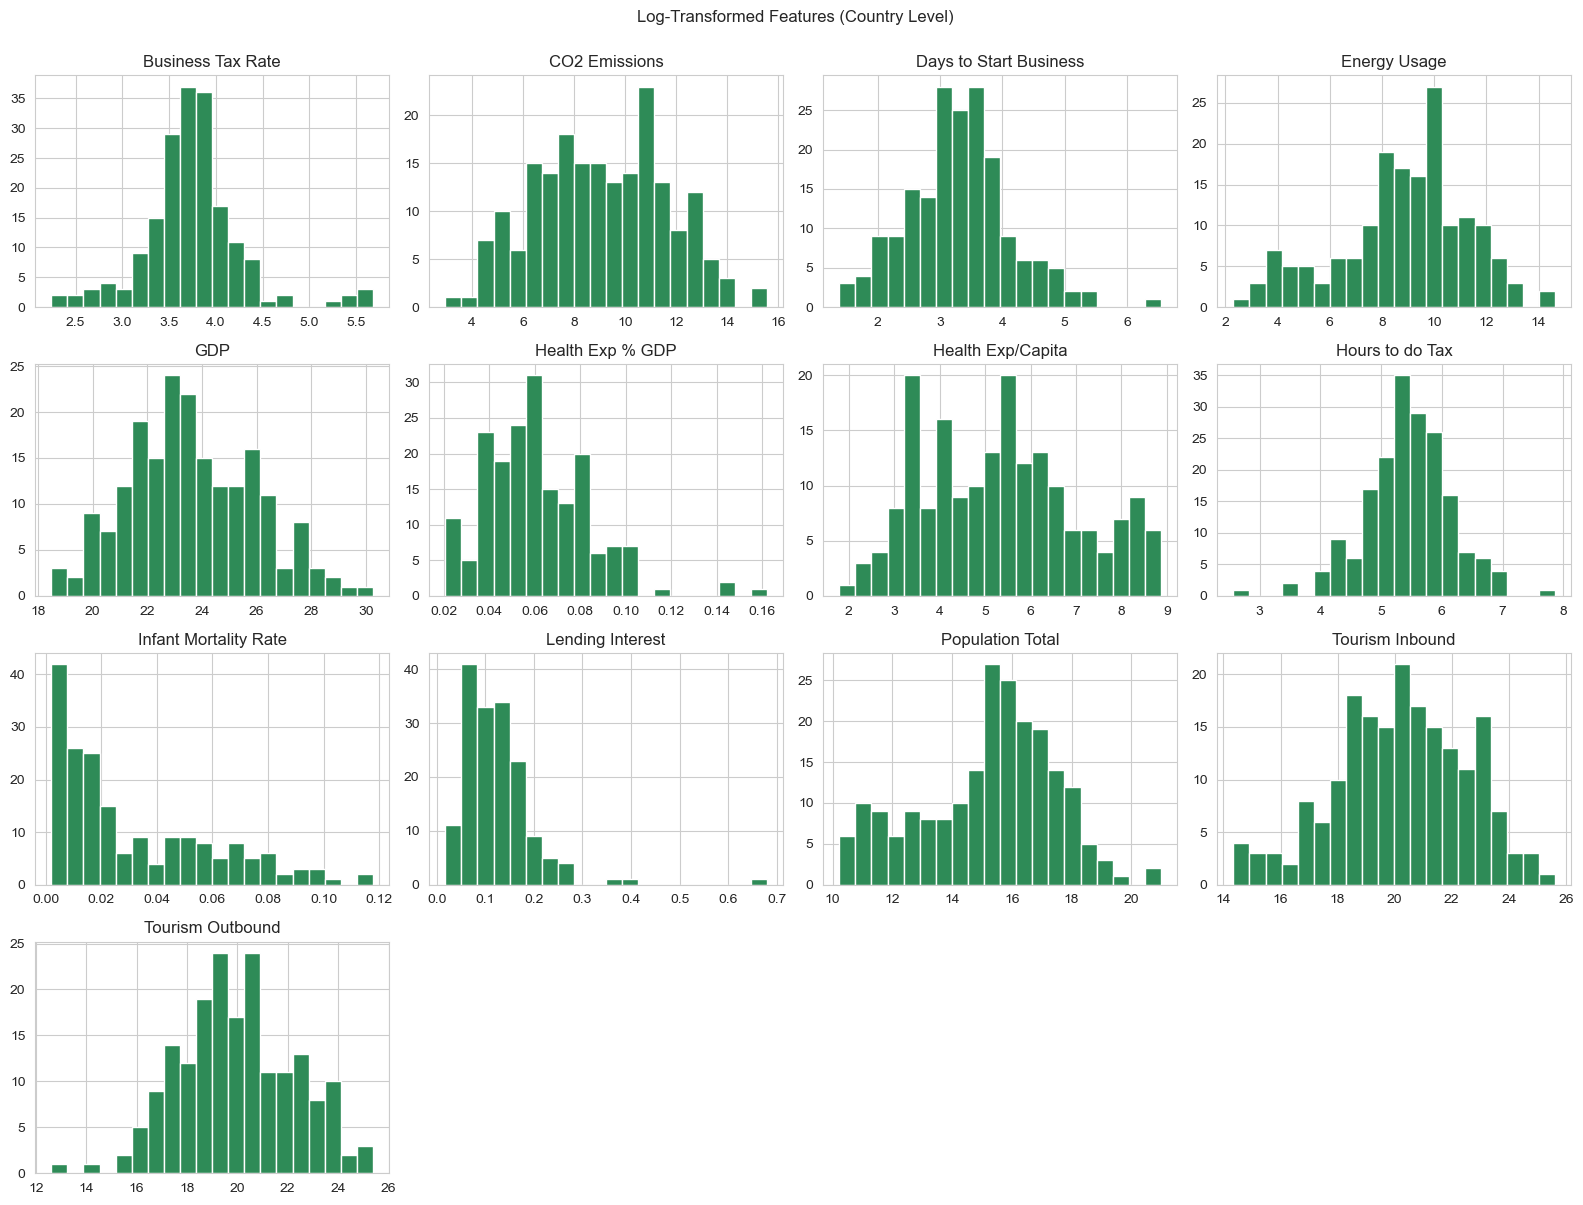

In [18]:
country_log[log_cols].hist(figsize=(16, 12), bins=20, color="seagreen")
plt.suptitle("Log-Transformed Features (Country Level)", y=1.00)
plt.tight_layout()
plt.show()

The log transform brings the heavy-tailed features much closer to symmetric (compare the skew table). This transformed table, `country_log`, is the basis for the correlation analysis and for the clustering step.

## 11. Correlation Analysis

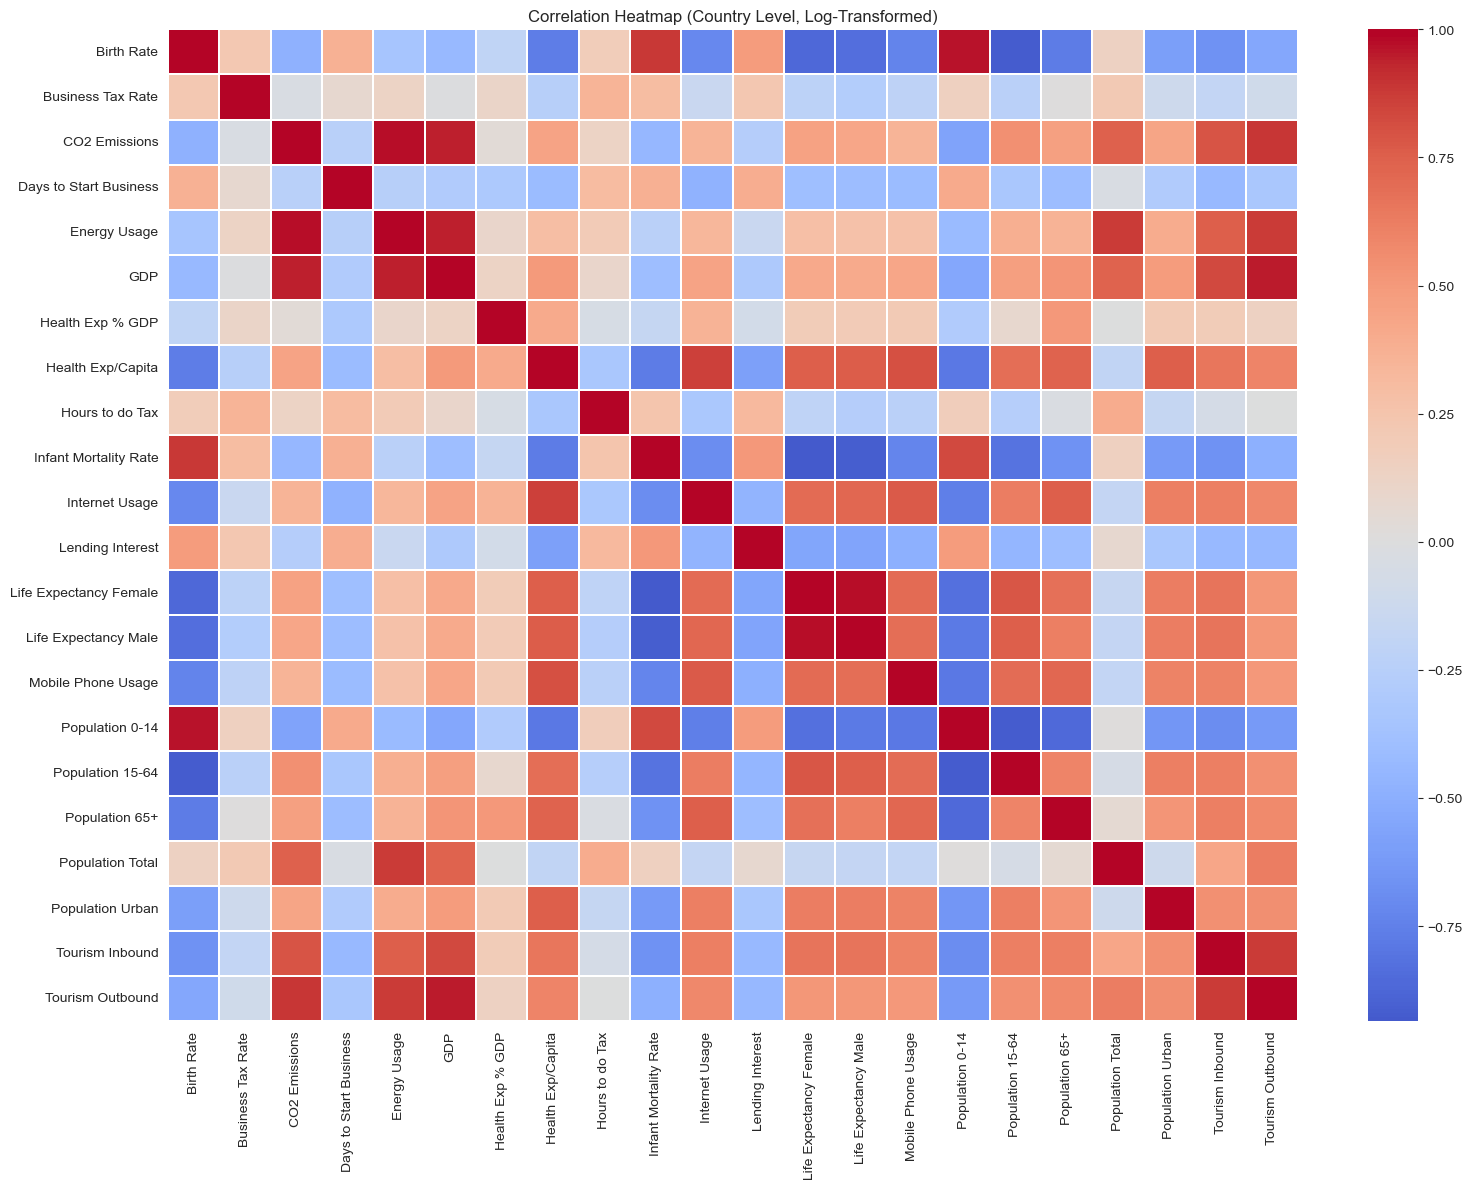

In [19]:
country_corr = country_log.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(country_corr, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Correlation Heatmap (Country Level, Log-Transformed)")
plt.tight_layout()
plt.show()

In [20]:
corr_pairs = country_corr.where(np.triu(np.ones(country_corr.shape), k=1).astype(bool)).stack().reset_index()
corr_pairs.columns = ["Feature 1", "Feature 2", "Corr"]
corr_pairs["Absolute Corr"] = corr_pairs["Corr"].abs()
corr_pairs = corr_pairs.sort_values("Absolute Corr", ascending=False)

display(corr_pairs.head(20))

,Feature 1,Feature 2,Corr,Absolute Corr
186,Life Expectancy Female,Life Expectancy Male,0.976432,0.976432
42,CO2 Emissions,Energy Usage,0.970125,0.970125
14,Birth Rate,Population 0-14,0.962716,0.962716
110,GDP,Tourism Outbound,0.947887,0.947887
43,CO2 Emissions,GDP,0.947039,0.947039
78,Energy Usage,GDP,0.946405,0.946405
155,Infant Mortality Rate,Life Expectancy Female,-0.935474,0.935474
210,Population 0-14,Population 15-64,-0.926386,0.926386
15,Birth Rate,Population 15-64,-0.926003,0.926003
156,Infant Mortality Rate,Life Expectancy Male,-0.912806,0.912806


In [21]:
high_corr = corr_pairs[corr_pairs["Absolute Corr"] >= 0.85]
print(f"{len(high_corr)} feature pairs with |correlation| >= 0.85")
display(high_corr[["Feature 1", "Feature 2", "Corr"]])

18 feature pairs with |correlation| >= 0.85


,Feature 1,Feature 2,Corr
186,Life Expectancy Female,Life Expectancy Male,0.976432
42,CO2 Emissions,Energy Usage,0.970125
14,Birth Rate,Population 0-14,0.962716
110,GDP,Tourism Outbound,0.947887
43,CO2 Emissions,GDP,0.947039
78,Energy Usage,GDP,0.946405
155,Infant Mortality Rate,Life Expectancy Female,-0.935474
210,Population 0-14,Population 15-64,-0.926386
15,Birth Rate,Population 15-64,-0.926003
156,Infant Mortality Rate,Life Expectancy Male,-0.912806


**Findings**
- Several groups of features are near-duplicates:
  - **Life expectancy:** `Life Expectancy Female` and `Life Expectancy Male` move almost together.
  - **Demographics:** `Birth Rate`, `Population 0-14`, `Population 15-64`, `Population 65+`, `Infant Mortality Rate` and life expectancy are strongly related. The three age shares also add up to ~1, so they are mathematically dependent.
  - **Economic size:** `GDP`, `CO2 Emissions`, `Energy Usage`, `Tourism Inbound/Outbound` and `Population Total` rise together.
- Keeping all of these would let one theme dominate the distance calculation in K-Means, so they are consolidated before clustering.

## 12. Summary of EDA Decisions

| Area | Finding | Decision for the clustering step |
|---|---|---|
| Data type | 5 columns stored as text (`$`, `,`, `%`) | Converted to numeric (done) |
| Useless columns | `Number of Records` constant; `Ease of Business` ~93% missing | Dropped (done) |
| Structure | 13 records per country | Aggregated to 208 countries using the median (done) |
| Outliers | Real differences in country size, not errors | **No capping**; log-transform skewed features (done) |
| Missing values | Up to ~22% missing at country level (`Lending Interest`, `Energy Usage`) | Impute in preprocessing (median or KNN); consider dropping countries with very many gaps |
| Multicollinearity | Life expectancy M/F, age-structure shares, and economic-size variables are highly correlated | Merge `Life Expectancy Female/Male` into one average; keep two of the three age shares (or drop `Population 15-64`); keep a smaller set from the economic-size group (e.g. `GDP`, `CO2 Emissions`) |
| Scaling | Features are on very different scales | Apply `StandardScaler` before K-Means |

**Next step:** feature selection → imputation → scaling → choosing *k* (elbow / silhouette) → K-Means / hierarchical clustering → cluster profiling.

---
# Part 2: Preprocessing, Model Building & Comparison

**Where we are:** Part 1 produced `country_log` – one row per country (208 rows), cleaned, with skewed features log-transformed. Part 2 turns it into clusters.

| Section | What happens | Why |
|---|---|---|
| 13 | Fill missing values | clustering cannot use empty cells |
| 14 | Scaling + PCA | put features on one scale and merge correlated ones |
| 15 | Four clustering models | K-Means, DBSCAN, Gaussian Mixture, Hierarchical |
| 16 | Model comparison | choose using Silhouette, Davies-Bouldin, Calinski-Harabasz |
| 17 | Save models | reuse them later (for example in an app) |
| 18 | Optional extended tuning | commented-out code that tests many settings |

### Link between Part 1 and Part 2
The modelling cells below (taken from the second notebook) use two names: **`df`** (the feature table) and **`columns`** (the list of feature names). In Part 1 the same data is called `country_log`, so the next cell simply connects the two names. Nothing is changed in the data.

In [22]:
# LINK: the pasted modelling cells expect the names `df` and `columns`
df = country_log.copy()            # one row per country (208 rows), already cleaned and log-transformed in Part 1
columns = df.columns.tolist()      # names of all 22 numeric indicators used for clustering

print("Countries:", df.shape[0], "| Features:", len(columns))

Countries: 208 | Features: 22


## 13. Fill Missing Values
About up to 22% of some indicators are still empty at country level (see Section 9). Skewed columns are filled with the **median**, the others with the **mean**, so no country has to be removed.

In [23]:
# STEP 1 - Fill missing values in SKEWED columns with the MEDIAN.
# The median is not pulled by extreme values, so it is safer for very uneven columns (GDP, CO2, ...).
# columns with very uneven (right-skewed) values
skewed_columns = [
    "Business Tax Rate",
    "CO2 Emissions",
    "Days to Start Business",
    "Energy Usage",
    "GDP",
    "Health Exp/Capita",
    "Lending Interest",
    "Population Total",
    "Tourism Inbound",
    "Tourism Outbound"
]

# go through each skewed column
for col in skewed_columns:
    # replace every missing value by the column median
    df[col] = df[col].fillna(df[col].median())

In [24]:
# STEP 2 - Fill missing values in the remaining columns with the MEAN.
# These columns are more symmetric, so the mean is a fair 'typical' value.
# go through all features
for col in columns:
    # only the columns not handled above
    if col not in skewed_columns:
        # replace every missing value by the column mean
        df[col] = df[col].fillna(df[col].mean())

In [25]:
# CHECK - every column must show 0 missing values before scaling.
df[columns].isnull().sum()

Birth Rate                0
Business Tax Rate         0
CO2 Emissions             0
Days to Start Business    0
Energy Usage              0
GDP                       0
Health Exp % GDP          0
Health Exp/Capita         0
Hours to do Tax           0
Infant Mortality Rate     0
Internet Usage            0
Lending Interest          0
Life Expectancy Female    0
Life Expectancy Male      0
Mobile Phone Usage        0
Population 0-14           0
Population 15-64          0
Population 65+            0
Population Total          0
Population Urban          0
Tourism Inbound           0
Tourism Outbound          0
dtype: int64

**Check:** the table above must show `0` for every column. If a number is above 0, run the two filling cells again.

## 14. Scaling & PCA
Indicators use very different units (population in millions, rates in %). **StandardScaler** puts them on the same scale. **PCA** then merges the correlated indicators (life expectancy, age shares, economy size) into a few independent components that keep **95 %** of the information. All clustering models below use these components (`X_pca`).

In [26]:
# STEP 3 - Scaling and PCA.
# StandardScaler: every feature gets mean 0 and std 1 so large-unit features do not dominate.
# PCA: merges correlated features into a few components that keep 95% of the information.
# The two asserts stop the code if any missing or infinite value is still present.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# feature table: one row per country, one column per indicator
X = df[columns].copy()
# stop if any value is still missing
assert X.notna().sum().sum() == X.size, "Missing values remain after imputation"
# stop if any value is infinite
assert np.isfinite(X.to_numpy()).all(), "Non-finite values detected"
# create the scaler
scaler = StandardScaler()
# learn mean/std and scale the data
X_scaled = scaler.fit_transform(X)
# keep as many components as needed for 95% of the variance
pca = PCA(n_components=0.95, svd_solver="full")
# transformed data used by ALL clustering models
X_pca = pca.fit_transform(X_scaled)
# how many features before / after PCA
print(f"Original columns: {X.shape[1]} | PCA columns: {X_pca.shape[1]}")
# share of information kept (should be about 95%)
print(f"Retained variance: {pca.explained_variance_ratio_.sum():.2%}")


Original columns: 22 | PCA columns: 11
Retained variance: 95.39%


In [27]:
# Put the PCA result into a table (PC1, PC2, ...) to see what the clustering models will use.
import pandas as pd

# table of the principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(X_pca.shape[1])]
)

# names of the components
print("PCA columns:")
print(pca_df.columns.tolist())

# first 5 countries in PCA space
display(pca_df.head())

PCA columns:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11']


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
0,4.302878,1.146855,0.914378,-2.492559,-0.321712,-0.771373,-0.239398,-1.043464,0.530407,0.117347,0.184072
1,-0.740475,-0.588741,-0.058393,1.034372,-0.823978,-0.800682,0.000400,-0.458834,0.153890,-0.068307,-0.231388
2,-0.372227,1.692588,-0.647220,1.102326,-1.293129,0.997847,0.055200,-0.123523,-0.151688,0.635746,-0.228168
3,0.031454,-0.843822,0.029429,0.156686,0.400220,0.782877,-0.080087,-0.792926,-0.677230,0.943175,0.725465
4,-1.362419,-2.326409,0.610474,0.257489,1.132822,1.321484,-0.283921,-0.425314,0.520157,-0.075459,0.472416


**How to read this:** the first print shows how many features were reduced to how many components; the second should be close to 95 %. `PC1`, `PC2`, ... are the new combined features.

## 15. Build the Clustering Models
Four algorithms are trained on `X_pca`. Each cluster number (0, 1, 2, ...) is stored in a `labels_...` variable, one value per country.

### Model 1 – K-Means
Splits countries into *k* groups around centre points. The **elbow plot** helps to choose *k*.

In [28]:
# MODEL 1 - K-Means with 4 clusters (n_init=10 -> 10 random starts, the best one is kept).
from sklearn.cluster import KMeans
# create the K-Means model with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# train it; one cluster number per country
labels_kmeans = kmeans.fit_predict(X_pca)
# cluster numbers and how many countries in each
print("K-Means clusters:", np.unique(labels_kmeans, return_counts=True))



K-Means clusters: (array([0, 1, 2, 3], dtype=int32), array([65, 44, 43, 56]))


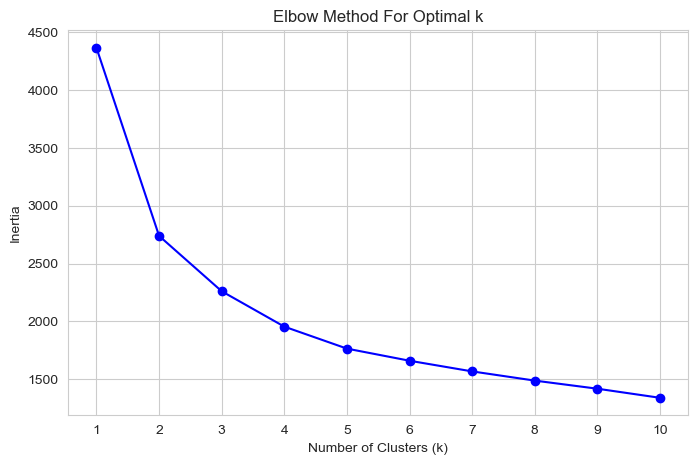

In [29]:
# ELBOW METHOD - run K-Means for k = 1 ... 10 and plot the inertia (within-cluster distance).
# Choose k where the curve stops dropping sharply (the 'elbow').
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np

# Define range of cluster counts to test
# will hold the inertia for each k
inertia = []
# try 1 to 10 clusters
K_range = range(1, 11)

# repeat for every k
for k in K_range:
    # FIX: temporary model named km_test so the main `kmeans` model (k=4) is not overwritten
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    # train the temporary model
    km_test.fit(X_pca)
    # store its inertia
    inertia.append(km_test.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
# elbow curve: k on x-axis, inertia on y-axis
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.xticks(K_range)
plt.grid(True)
plt.show()

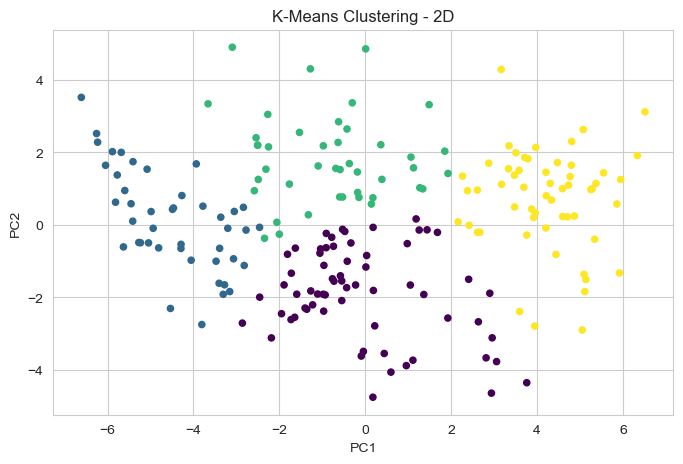

In [30]:
# 2D plot of the K-Means clusters on the first two principal components.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# one dot per country, coloured by its cluster
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_kmeans,
    cmap='viridis',
    s=20
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clustering - 2D')
plt.show()

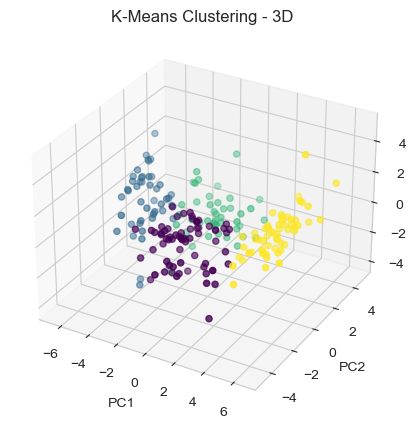

In [31]:
# 3D plot of the K-Means clusters on the first three principal components.
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 5))
# 3D axis
ax = fig.add_subplot(111, projection='3d')

# one point per country, coloured by cluster
ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=labels_kmeans,
    cmap='viridis',
    s=20
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('K-Means Clustering - 3D')

plt.show()

**How to read the elbow plot:** inertia always falls as *k* grows; choose the *k* where the drop becomes small (the bend of the elbow).

### Model 2 – DBSCAN
Finds dense groups and marks isolated countries as **noise (-1)**. It does not need the number of clusters, but depends on `eps` and `min_samples`.

In [32]:
# MODEL 2 - DBSCAN: groups points that are close together; isolated points get label -1 (noise).
# eps = neighbourhood radius, min_samples = points needed to form a dense region.
from sklearn.cluster import DBSCAN
# create DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=10)
# train it; -1 means noise
labels_dbscan = dbscan.fit_predict(X_pca)
# cluster numbers and counts (-1 = noise)
print("DBSCAN labels (-1 means noise):", np.unique(labels_dbscan, return_counts=True))


DBSCAN labels (-1 means noise): (array([-1,  0,  1]), array([79, 96, 33]))


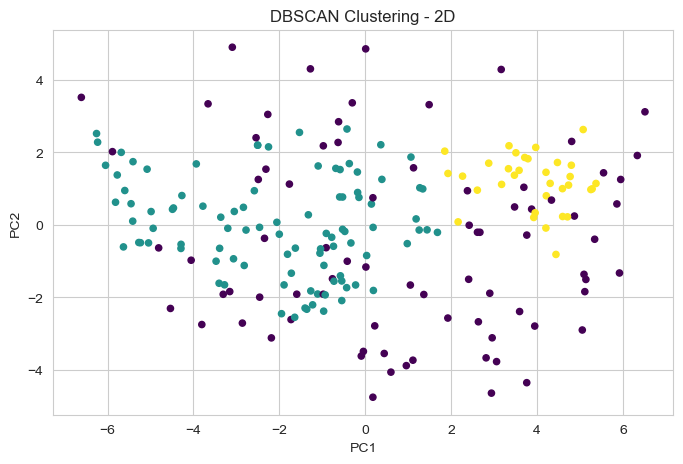

In [33]:
# 2D plot of the DBSCAN result (the noise points are shown with their own colour).
plt.figure(figsize=(8, 5))
# one dot per country, coloured by DBSCAN label
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=labels_dbscan, cmap='viridis', s=20)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('DBSCAN Clustering - 2D')
plt.show()

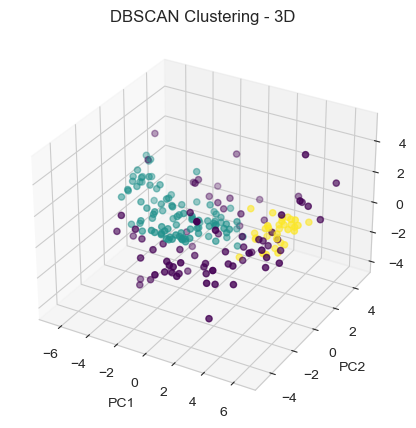

In [34]:
# 3D plot of the DBSCAN result.
fig = plt.figure(figsize=(8, 5))
# 3D axis
ax = fig.add_subplot(111, projection='3d')

# one point per country
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
           c=labels_dbscan, cmap='viridis', s=20)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('DBSCAN Clustering - 3D')
plt.show()

### Model 3 – Gaussian Mixture (GMM)
Each cluster is a bell-shaped group, so clusters can have different sizes and shapes.

In [35]:
# MODEL 3 - Gaussian Mixture (GMM) with 4 components: each cluster is a bell-shaped (Gaussian) group.
from sklearn.mixture import GaussianMixture
# create the Gaussian Mixture with 4 components
gmm = GaussianMixture(n_components=4, random_state=42, reg_covar=1e-5)
# train it; one cluster number per country
labels_gmm = gmm.fit_predict(X_pca)
# cluster numbers and counts
print("GMM clusters:", np.unique(labels_gmm, return_counts=True))


GMM clusters: (array([0, 1, 2, 3]), array([69, 45, 22, 72]))


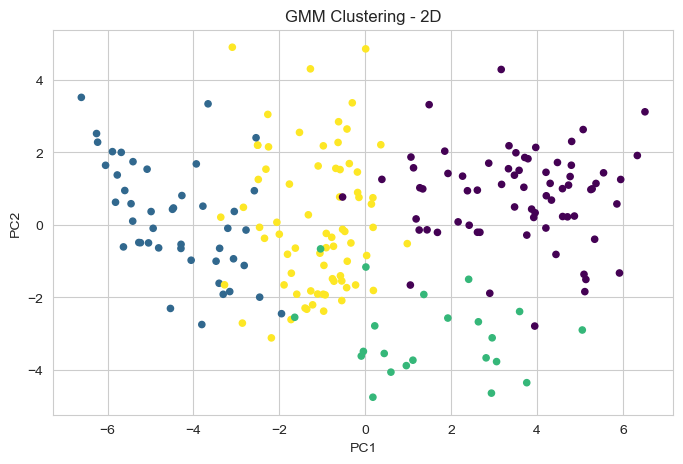

In [36]:
# 2D plot of the GMM clusters.
plt.figure(figsize=(8, 5))
# one dot per country, coloured by GMM cluster
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=labels_gmm, cmap='viridis', s=20)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('GMM Clustering - 2D')
plt.show()

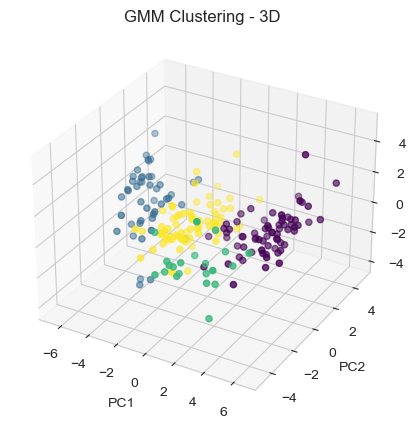

In [37]:
# 3D plot of the GMM clusters.
fig = plt.figure(figsize=(8, 5))
# 3D axis
ax = fig.add_subplot(111, projection='3d')

# one point per country
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
           c=labels_gmm, cmap='viridis', s=20)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('GMM Clustering - 3D')
plt.show()

### Model 4 – Hierarchical (Agglomerative)
Starts with every country alone and repeatedly merges the two closest groups (Ward linkage).

In [38]:
# MODEL 4 - Hierarchical (Agglomerative) clustering with 4 clusters and Ward linkage
# (starts with every country alone and merges the closest groups step by step).
from sklearn.cluster import AgglomerativeClustering

# create the hierarchical model (Ward linkage)
hierarchical = AgglomerativeClustering(n_clusters=4, linkage='ward')
# train it; one cluster number per country
labels_hierarchical = hierarchical.fit_predict(X_pca)

# cluster numbers and counts
print("Hierarchical clusters:", np.unique(labels_hierarchical, return_counts=True))

Hierarchical clusters: (array([0, 1, 2, 3]), array([109,  54,  26,  19]))


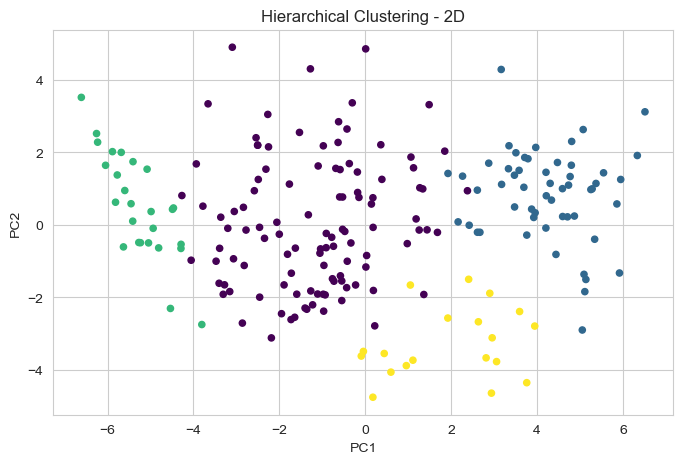

In [39]:
# 2D plot of the Hierarchical clusters.
plt.figure(figsize=(8, 5))
# one dot per country, coloured by cluster
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=labels_hierarchical, cmap='viridis', s=20)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Hierarchical Clustering - 2D')
plt.show()

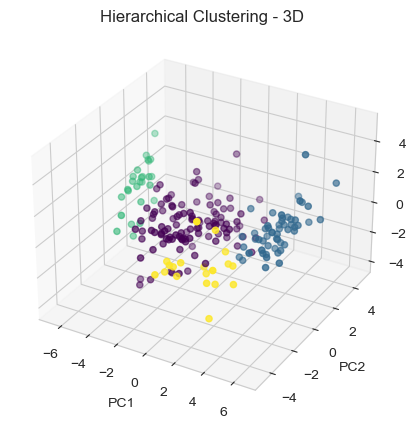

In [40]:
# 3D plot of the Hierarchical clusters.
fig = plt.figure(figsize=(8, 5))
# 3D axis
ax = fig.add_subplot(111, projection='3d')

# one point per country
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
           c=labels_hierarchical, cmap='viridis', s=20)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('Hierarchical Clustering - 3D')
plt.show()

## 16. Compare the Models
| Metric | Better when |
|---|---|
| Silhouette | higher |
| Davies-Bouldin | **lower** |
| Calinski-Harabasz | higher |

In [41]:
# COMPARE THE 4 MODELS with three metrics.
# Silhouette (higher = better) | Davies-Bouldin (LOWER = better) | Calinski-Harabasz (higher = better)
# Coverage = share of countries that received a cluster (DBSCAN noise is not counted).
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# scores one set of labels with the 3 metrics
def evaluate_clustering(name, labels):
    # convert to a NumPy array
    labels = np.asarray(labels)
    # True for points that belong to a cluster (not noise)
    mask = labels != -1
    # number of clusters found
    count = np.unique(labels[mask]).size
    # share of countries that got a cluster
    coverage = mask.mean()
    # one row of the comparison table
    result = {"Model": name, "Clusters": count, "Coverage": round(coverage, 3), "Noise points": int((~mask).sum()), "Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    # the metrics need at least 2 clusters
    if count >= 2 and mask.sum() > count:
        # keep only the clustered points
        features, y = X_pca[mask], labels[mask]
        # how well countries fit their own cluster (higher = better)
        result["Silhouette"] = silhouette_score(features, y, sample_size=min(1000, len(y)), random_state=42)
        # similarity between clusters (lower = better)
        result["Davies-Bouldin"] = davies_bouldin_score(features, y)
        # between-cluster vs within-cluster spread (higher = better)
        result["Calinski-Harabasz"] = calinski_harabasz_score(features, y)
    # give the row back
    return result

# score all four models and sort by silhouette
comparison = pd.DataFrame([
    evaluate_clustering("K-Means", labels_kmeans),
    evaluate_clustering("Hierarchical", labels_hierarchical),
    evaluate_clustering("DBSCAN", labels_dbscan),
    evaluate_clustering("GMM", labels_gmm)
]).sort_values("Silhouette", ascending=False, na_position="last").reset_index(drop=True)
# show the comparison table
display(comparison.round(3))
# models that cluster at least 80% of the countries
eligible = comparison[(comparison["Coverage"] >= 0.8) & comparison["Silhouette"].notna()]
# name the best silhouette among them
if not eligible.empty:
    print("Best silhouette among models with >=80% coverage:", eligible.iloc[0]["Model"])
# otherwise ask the user to inspect the results
else:
    print("No model meets the >=80% coverage threshold; inspect results before choosing.")


,Model,Clusters,Coverage,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,DBSCAN,2,0.62,79,0.394,0.873,99.087
1,K-Means,4,1.00,0,0.245,1.345,83.820
2,Hierarchical,4,1.00,0,0.219,1.216,74.610
3,GMM,4,1.00,0,0.203,1.515,71.323


Best silhouette among models with >=80% coverage: K-Means


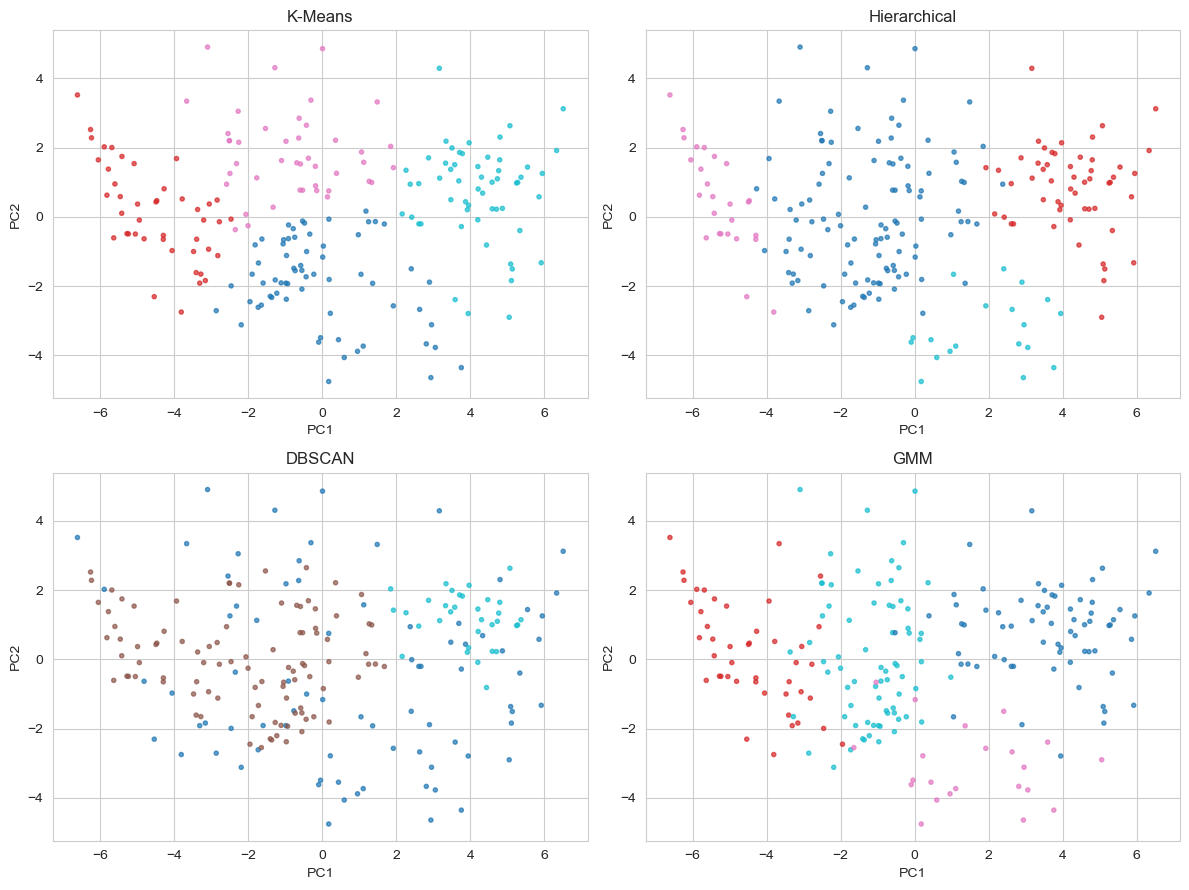

In [42]:
# Side-by-side plots of the 4 models on PC1 vs PC2.
import matplotlib.pyplot as plt
# 2 x 2 grid of plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# one plot per model
for ax, (name, labels) in zip(axes.flat, [("K-Means", labels_kmeans), ("Hierarchical", labels_hierarchical), ("DBSCAN", labels_dbscan), ("GMM", labels_gmm)]):
    # countries coloured by that model's clusters
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=9, cmap="tab10", alpha=0.7)
    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
# avoid overlapping labels
plt.tight_layout()
plt.show()


**How to read the comparison:** choose the model with a high Silhouette and Calinski-Harabasz and a low Davies-Bouldin. Check **Coverage**: a model that leaves many countries as noise (DBSCAN) is less useful even if its score looks good. The plots show whether the groups look clearly separated.

## 17. Save the Models
The scaler, PCA and all four models are written to `.pkl` files in the notebook's folder, so new data can be scaled and clustered the same way later (for example in a Streamlit app).

In [43]:
# SAVE the scaler, PCA and the four models to files (.pkl) so they can be reused (for example in an app).

import joblib

# StandardScaler fitted on the data
joblib.dump(scaler, "scaler.pkl")
# PCA fitted on the data
joblib.dump(pca, "pca.pkl")
# K-Means model
joblib.dump(kmeans, "kmeans.pkl")
# DBSCAN model
joblib.dump(dbscan, "dbscan.pkl")
# Gaussian Mixture model
joblib.dump(gmm, "gmm.pkl")
# FIX: the variable is `hierarchical` (the original `agglo` was never defined); file name kept as agglo.pkl
joblib.dump(hierarchical, "agglo.pkl")

# confirmation message
print("All models saved successfully!")


All models saved successfully!


In [44]:
# Troubleshooting cell: lists all variables in the notebook (optional).
%whos

Variable                  Type                       Data/Info
--------------------------------------------------------------
AgglomerativeClustering   type                       <class 'sklearn.cluster._<...>AgglomerativeClustering'>
Axes3D                    type                       <class 'mpl_toolkits.mplot3d.axes3d.Axes3D'>
DBSCAN                    type                       <class 'sklearn.cluster._dbscan.DBSCAN'>
GaussianMixture           ABCMeta                    <class 'sklearn.mixture._<...>mixture.GaussianMixture'>
KMeans                    ABCMeta                    <class 'sklearn.cluster._kmeans.KMeans'>
K_range                   range                      range(1, 11)
PCA                       ABCMeta                    <class 'sklearn.decomposition._pca.PCA'>
RANDOM_STATE              int                        42
StandardScaler            type                       <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                         DataFrame          

### Extra files for the Streamlit app
The app needs two more things besides the `.pkl` models: (1) the **feature list and the log-transformed columns**, so it can prepare a new country exactly like Part 1 and Part 2, and (2) the **final country table** (raw indicator values, the PCA coordinates and the cluster of each country from K-Means and GMM) for the map, profiles and 'similar countries' list. K-Means and GMM are used in the app because they can assign a *new* country to a cluster (DBSCAN and Hierarchical cannot).

In [45]:
# Files used by the Streamlit app
# 1) feature names and the columns that were log-transformed in Part 1
joblib.dump({"columns": columns, "log_cols": log_cols}, "app_info.pkl")

# 2) final country table: raw indicator values + PCA coordinates + cluster of each country
pcs = pd.DataFrame(X_pca, index=df.index, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
results = country_df.join(pcs)                 # country_df = raw (non-log) median values per country
results["Cluster_KMeans"] = labels_kmeans      # cluster from the K-Means model
results["Cluster_GMM"] = labels_gmm            # cluster from the Gaussian Mixture model
results.to_csv("country_results.csv")

print("Saved: app_info.pkl and country_results.csv")

Saved: app_info.pkl and country_results.csv


---
## 19. Project Summary
- **Part 1 (EDA):** text columns converted to numbers, unusable columns dropped, records combined into one row per country, skewed indicators log-transformed.
- **Part 2 (Modelling):** missing values filled, features scaled, PCA keeps 95 % of the information, four clustering models trained and compared with three metrics.
- **Result:** the chosen model and number of clusters come from the comparison table in Section 16 and the plots in Section 15.
- **Saved files:** `scaler.pkl`, `pca.pkl`, `kmeans.pkl`, `dbscan.pkl`, `gmm.pkl`, `agglo.pkl`, plus `app_info.pkl` and `country_results.csv` used by the Streamlit app.